# Deep Q-Network (DQN) Training on CartPole-v1 (PyTorch)

This notebook implements the Deep Q-Learning (DQN) algorithm to solve the classic **CartPole-v1** environment using **PyTorch** and **Gymnasium**.

### Key Workflow Sections:
1. **Imports and Environment Setup**
2. **Neural Network Architecture (DQN)**
3. **Hyperparameters and Initialization**
4. **Epsilon-Greedy Action Selection**
5. **Experience Replay and Optimization**
6. **Training Loop**
7. **Saving the Trained Model**
8. **Visualizing Training Performance**

---

## 1. Imports and Environment Setup
Load required dependencies and initialize the Gymnasium `CartPole-v1` environment.

In [1]:
import os
import random
from collections import deque
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Create the CartPole environment
env = gym.make("CartPole-v1")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)


## 2. Neural Network Architecture (DQN)
The network approximates the action-value function $Q(s, a)$, taking the 4-dimensional state vector as input and producing Q-values for each of the 2 discrete actions.

In [2]:
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, output_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

## 3. Hyperparameters and Initialization
Define training parameters, instantiate policy and target networks, and set up the replay memory buffer.

In [3]:
# Hyperparameters
learning_rate = 0.001
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995
batch_size = 64
target_update_freq = 1000
memory_size = 10000
episodes = 1000

# Initialize Q-networks
input_dim = env.observation_space.shape[0]
output_dim = env.action_space.n
policy_net = DQN(input_dim, output_dim)
target_net = DQN(input_dim, output_dim)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=learning_rate)
memory = deque(maxlen=memory_size)

## 4. Epsilon-Greedy Action Selection
Balance exploration (random uniform action) and exploitation (argmax of predicted Q-values) based on the current $\epsilon$ value.

In [4]:
def select_action(state, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample()  # Explore
    else:
        state = torch.FloatTensor(state).unsqueeze(0)
        q_values = policy_net(state)
        return torch.argmax(q_values).item()  # Exploit

## 5. Experience Replay and Optimization
Sample mini-batches from replay memory to compute Bellman targets and update policy network parameters via Mean Squared Error (MSE) loss.

In [5]:
def optimize_model():
    if len(memory) < batch_size:
        return

    batch = random.sample(memory, batch_size)
    state_batch, action_batch, reward_batch, next_state_batch, done_batch = zip(*batch)

    state_batch = torch.FloatTensor(np.array(state_batch))
    action_batch = torch.LongTensor(action_batch).unsqueeze(1)
    reward_batch = torch.FloatTensor(reward_batch)
    next_state_batch = torch.FloatTensor(np.array(next_state_batch))
    done_batch = torch.FloatTensor(done_batch)

    # Compute Q-values for current states
    q_values = policy_net(state_batch).gather(1, action_batch).squeeze()

    # Compute target Q-values using the target network
    with torch.no_grad():
        max_next_q_values = target_net(next_state_batch).max(1)[0]
        target_q_values = reward_batch + gamma * max_next_q_values * (1 - done_batch)

    loss = nn.MSELoss()(q_values, target_q_values)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

## 6. Training Loop
Run training over 1000 episodes, updating policy weights after each step and synchronizing target network weights periodically.

In [6]:
rewards_per_episode = []
steps_done = 0

for episode in range(episodes):
    state, info = env.reset()
    episode_reward = 0
    done = False

    while not done:
        # Select action
        action = select_action(state, epsilon)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Store transition in memory
        memory.append((state, action, reward, next_state, done))

        # Update state
        state = next_state
        episode_reward += reward

        # Optimize model
        optimize_model()

        # Update target network periodically
        if steps_done % target_update_freq == 0:
            target_net.load_state_dict(policy_net.state_dict())

        steps_done += 1

    # Decay epsilon
    epsilon = max(epsilon_min, epsilon_decay * epsilon)

    rewards_per_episode.append(episode_reward)

    if (episode + 1) % 10 == 0:
        avg_reward = float(np.mean(rewards_per_episode[-10:]))
        print(f"Episode {episode + 1}/{episodes} | Reward: {episode_reward:.1f} | Avg Reward (last 10): {avg_reward:.2f} | Epsilon: {epsilon:.3f}")

env.close()

Episode 10/1000 | Reward: 25.0 | Avg Reward (last 10): 26.20 | Epsilon: 0.951
Episode 20/1000 | Reward: 11.0 | Avg Reward (last 10): 24.70 | Epsilon: 0.905
Episode 30/1000 | Reward: 22.0 | Avg Reward (last 10): 20.80 | Epsilon: 0.860
Episode 40/1000 | Reward: 35.0 | Avg Reward (last 10): 21.60 | Epsilon: 0.818
Episode 50/1000 | Reward: 32.0 | Avg Reward (last 10): 24.90 | Epsilon: 0.778
Episode 60/1000 | Reward: 9.0 | Avg Reward (last 10): 21.40 | Epsilon: 0.740
Episode 70/1000 | Reward: 19.0 | Avg Reward (last 10): 15.10 | Epsilon: 0.704
Episode 80/1000 | Reward: 11.0 | Avg Reward (last 10): 19.30 | Epsilon: 0.670
Episode 90/1000 | Reward: 28.0 | Avg Reward (last 10): 17.50 | Epsilon: 0.637
Episode 100/1000 | Reward: 11.0 | Avg Reward (last 10): 17.00 | Epsilon: 0.606
Episode 110/1000 | Reward: 29.0 | Avg Reward (last 10): 19.20 | Epsilon: 0.576
Episode 120/1000 | Reward: 9.0 | Avg Reward (last 10): 17.00 | Epsilon: 0.548
Episode 130/1000 | Reward: 36.0 | Avg Reward (last 10): 21.20 |

## 7. Saving the Trained Model
Save the policy network state dictionary to the `models/` directory for subsequent evaluation.

In [7]:
models_dir = os.path.join(".", "models")
os.makedirs(models_dir, exist_ok=True)
model_path = os.path.join(models_dir, "dqn_cartpole_torch.pth")
torch.save(policy_net.state_dict(), model_path)
print(f"Model successfully saved to {model_path}")

Model successfully saved to .\models\dqn_cartpole_torch.pth


## 8. Visualizing Training Performance
Plot the rewards per episode to evaluate training convergence and stability.

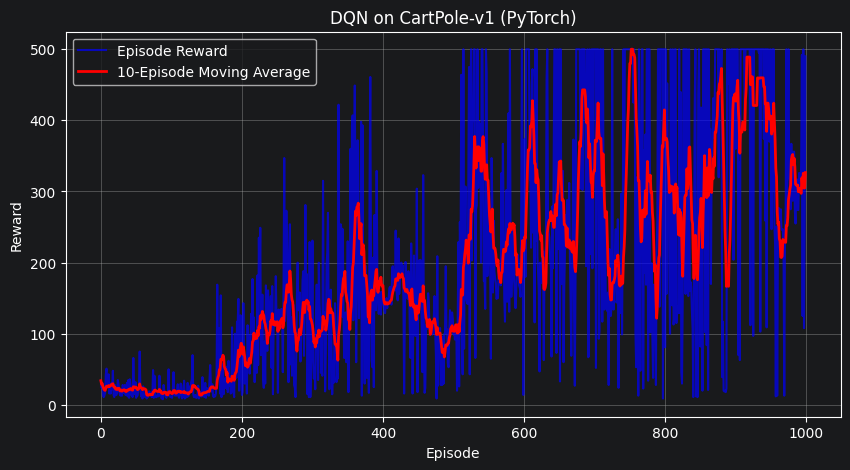

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(rewards_per_episode, label="Episode Reward", color="blue", alpha=0.7)
if len(rewards_per_episode) >= 10:
    rolling_avg = [np.mean(rewards_per_episode[max(0, i-9):i+1]) for i in range(len(rewards_per_episode))]
    plt.plot(rolling_avg, label="10-Episode Moving Average", color="red", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN on CartPole-v1 (PyTorch)")
plt.legend()
plt.grid(True)
plt.show()